# Знакомство с датасетами Wi-Fi CSI для детекции движения

Цель блока: для каждого датасета (**NTU-Fi HAR, UT-HAR, Widar 3.0, NTU-Fi HumanID, Wallhack1.8k**, а также **3DO** по ссылке из саммари) посмотреть:

1. как устроены файлы и папки;
2. форму данных (антенны, поднесущие, длина окна, амплитуда/комплексный CSI);
3. какие есть классы и как они распределены;
4. как CSI выглядит для разных классов (спектрограмма, отдельные поднесущие, «энергия движения»);
5. есть ли явный класс «нет человека / нет движения» (нужен для бинарной задачи).

**Как пользоваться.** Скачайте датасеты, поправьте пути в ячейке с `PATHS`, затем запускайте секции. Каждая секция независима: если данных нет, она просто пропустится.

**Где брать данные**

| Датасет | Источник |
|---|---|
| NTU-Fi HAR, NTU-Fi HumanID, UT-HAR | репозиторий бенчмарка SenseFi (`xyanchen/WiFi-CSI-Sensing-Benchmark`), ссылки на данные в README |
| Widar 3.0 | сайт проекта Widar 3.0 (Tsinghua), сырой CSI очень тяжёлый, для знакомства хватит части |
| Wallhack1.8k | Zenodo, record 13950918 (код: `StrohmayerJ/wallhack1.8k`) |
| 3DO | Zenodo, record 10925351 (код: `StrohmayerJ/3DO`) |

> Форматы NTU-Fi, UT-HAR и Widar написаны по памяти, поэтому в загрузчиках есть проверки и печать структуры. Если что-то не совпало, ориентируйтесь на вывод `tree()` и README датасета.

## 0. Настройки и вспомогательные функции

In [4]:
import os, re, ast, json, traceback, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# ---------- ПУТИ: поправьте под себя ----------
DATA_ROOT = Path("./data")
PATHS = {
    "NTU-Fi_HAR":     DATA_ROOT / "NTU-Fi_HAR",
    "NTU-Fi_HumanID": DATA_ROOT / "NTU-Fi-HumanID",
    "UT_HAR":         DATA_ROOT / "UT_HAR",
    "Widar_raw":      DATA_ROOT / "Widar3.0" / "CSI",
    "Widar_BVP":      DATA_ROOT / "Widar3.0" / "BVP",
    "Wallhack1.8k":   DATA_ROOT / "wallhack1.8k",
    "3DO":            DATA_ROOT / "3DO",
}

SUMMARY = []                                       # строки итоговой таблицы
ENERGY = defaultdict(lambda: defaultdict(list))    # ENERGY[датасет][класс] -> [motion_score, ...]

def have(path):
    ok = path is not None and Path(path).exists()
    if not ok:
        print(f"[пропуск] путь не найден: {path}")
    return ok

def run(fn, *args, **kw):
    """Запуск секции так, чтобы ошибка в одной не ломала остальные."""
    try:
        fn(*args, **kw)
    except Exception:
        traceback.print_exc()

def tree(root, max_depth=3, max_items=8):
    root = Path(root)
    def walk(p, depth):
        entries = sorted(p.iterdir(), key=lambda x: (x.is_file(), x.name))
        dirs  = [e for e in entries if e.is_dir()]
        files = [e for e in entries if e.is_file()]
        pad = "    " * depth
        for d in dirs[:max_items]:
            print(f"{pad}{d.name}/   ({sum(1 for _ in d.iterdir())} элементов)")
            if depth + 1 < max_depth:
                walk(d, depth + 1)
        if len(dirs) > max_items:
            print(f"{pad}... ещё {len(dirs) - max_items} папок")
        for f in files[:max_items]:
            print(f"{pad}{f.name}   {f.stat().st_size / 1e6:.2f} MB")
        if len(files) > max_items:
            print(f"{pad}... ещё {len(files) - max_items} файлов")
    print(root.resolve())
    walk(root, 0)

def describe(a, name="array"):
    a = np.asarray(a)
    line = f"{name}: shape={a.shape}, dtype={a.dtype}"
    if np.iscomplexobj(a):
        a = np.abs(a)
        line += " (комплексный, статистика по |x|)"
    a = a.astype(float)
    fin = np.isfinite(a)
    if fin.any():
        line += (f", min={a[fin].min():.3g}, max={a[fin].max():.3g}, "
                 f"mean={a[fin].mean():.3g}, std={a[fin].std():.3g}")
    line += f", nan={np.isnan(a).sum()}, inf={np.isinf(a).sum()}"
    print(line)

def to_TF(x):
    """Приводит массив к виду (время T, признаки F): время = более длинная ось."""
    x = np.squeeze(np.asarray(x))
    if x.ndim > 2:
        x = x.reshape(x.shape[0], -1)
    if x.ndim == 2 and x.shape[0] < x.shape[1]:
        x = x.T
    return x

def motion_curve(amp, win=50):
    """Скользящее std / mean по времени, усреднённое по поднесущим.
    Масштабно-инвариантная «энергия движения»: у статичной сцены близка к нулю."""
    df = pd.DataFrame(np.asarray(amp, dtype=float))
    win = int(max(2, min(win, len(df) // 4)))
    r = df.rolling(win)
    return (r.std() / (r.mean().abs() + 1e-9)).mean(axis=1).values

def motion_score(amp, win=50):
    return float(np.nanmean(motion_curve(amp, win)))

def plot_csi(amp, fs=None, title="", win=50, n_lines=3, max_t=4000):
    """Спектрограмма амплитуды + несколько поднесущих + энергия движения."""
    amp = np.asarray(amp, dtype=float)[:max_t]
    T, F = amp.shape
    t = np.arange(T) / fs if fs else np.arange(T)
    xl = "время, с" if fs else "отсчёт (пакет)"
    fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True,
                           gridspec_kw={"height_ratios": [2, 1.3, 1]})
    im = ax[0].imshow(amp.T, aspect="auto", origin="lower", extent=[t[0], t[-1], 0, F])
    ax[0].set_ylabel("поднесущая / признак"); ax[0].grid(False)
    fig.colorbar(im, ax=ax[0], pad=0.01, label="амплитуда")
    for i in np.linspace(0, F - 1, n_lines).astype(int):
        ax[1].plot(t, amp[:, i], lw=0.8, label=f"#{i}")
    ax[1].set_ylabel("амплитуда"); ax[1].legend(ncol=n_lines, fontsize=8, loc="upper right")
    ax[2].plot(t, motion_curve(amp, win), color="k", lw=1)
    ax[2].set_ylabel("энергия\nдвижения"); ax[2].set_xlabel(xl)
    fig.suptitle(title); fig.tight_layout(); plt.show()

def parse_csi_cell(s):
    """Строка вида '[12, -3, ...]' из csv ESP32 -> комплексный вектор.
    В ESP-IDF пары идут как (imag, real)."""
    if isinstance(s, str):
        try:
            arr = np.array(ast.literal_eval(s), dtype=float)
        except Exception:
            arr = np.fromstring(s.strip("[] \n"), sep=" ")
    else:
        arr = np.asarray(s, dtype=float)
    return arr[1::2] + 1j * arr[0::2]

## 1. NTU-Fi HAR и NTU-Fi HumanID

Из бенчмарка SenseFi. Ожидаемый формат: папки `train_amp/<класс>/*.mat` и `test_amp/<класс>/*.mat`, в каждом `.mat` матрица амплитуд `CSIamp` примерно `(342, 2000)`: 342 = 3 антенны × 114 поднесущих, 2000 = время. В SenseFi её прореживают до `3×114×500`.

- **HAR**: классы активностей (box, circle, clean, fall, run, walk); класса «нет движения» нет.
- **HumanID**: класс = человек (идентификация по походке); все сэмплы содержат ходьбу.

In [ ]:
def load_mat_amp(path):
    m = sio.loadmat(path)
    if "CSIamp" in m:
        x = m["CSIamp"]
    else:  # на случай другого ключа берём самый большой числовой массив
        arrs = {k: v for k, v in m.items() if isinstance(v, np.ndarray) and v.dtype.kind in "fiuc"}
        key = max(arrs, key=lambda k: arrs[k].size)
        print(f"  ключ 'CSIamp' не найден, беру '{key}'")
        x = arrs[key]
    x = x.astype(float)
    x[~np.isfinite(x)] = 0
    return x

def explore_ntu(name, root, max_plot=3, per_class_score=8):
    if not have(root): return
    root = Path(root)
    print(f"===== {name} =====")
    tree(root, 3)
    files = sorted(root.rglob("*.mat"))
    print("\n.mat файлов:", len(files))
    if not files: return
    rel = [f.relative_to(root).parts for f in files]
    df = pd.DataFrame({"path": files,
                       "split": [p[0] if len(p) > 2 else "root" for p in rel],
                       "cls": [f.parent.name for f in files]})
    print("\nРаспределение (строки: класс, столбцы: split):")
    print(df.groupby(["cls", "split"]).size().unstack(fill_value=0))

    x0 = load_mat_amp(files[0])
    describe(x0, "\nпервый файл")
    print("-> интерпретация: строки =", x0.shape[0], "(антенны × поднесущие), столбцы =", x0.shape[1], "(время)")

    classes = sorted(df.cls.unique())
    for c in classes[:max_plot]:
        f = df[df.cls == c].path.iloc[0]
        plot_csi(to_TF(load_mat_amp(f)), title=f"{name} · класс «{c}» · {f.name}", win=50)

    for c in classes:
        for f in df[df.cls == c].path.iloc[:per_class_score]:
            ENERGY[name][c].append(motion_score(to_TF(load_mat_amp(f))))

    SUMMARY.append(dict(dataset=name, samples=len(files), sample_shape=str(x0.shape),
                        n_classes=len(classes), classes=", ".join(classes[:14]),
                        has_idle_class="не очевидно" if len(classes) else "?",
                        note="только амплитуда; ось времени 2000 отсчётов"))

run(explore_ntu, "NTU-Fi_HAR", PATHS["NTU-Fi_HAR"])

In [ ]:
run(explore_ntu, "NTU-Fi_HumanID", PATHS["NTU-Fi_HumanID"], max_plot=2)

## 2. UT-HAR

Intel 5300: 3 антенны × 30 поднесущих = 90 признаков, окно по времени 250 отсчётов. В версии из SenseFi это набор файлов `X_train / X_val / X_test / y_train / y_val / y_test` (формат numpy, хотя расширение может быть `.csv`). Форма `X`: `(N, 250, 90)` или `(N, 1, 250, 90)`.

Имена классов ниже взяты по порядку из SenseFi, **сверьте с README**.

===== UT-HAR =====
C:\Users\ditriy\Desktop\wifi-csi-scene\data\UT_HAR
.ipynb_checkpoints/   (0 элементов)
data/   (3 элементов)
    X_test.csv   90.00 MB
    X_train.csv   715.86 MB
    X_val.csv   89.28 MB
label/   (3 элементов)
    y_test.csv   0.00 MB
    y_train.csv   0.03 MB
    y_val.csv   0.00 MB
X_train: shape=(3977, 250, 90), dtype=float64, min=-10.7, max=30.5, mean=17.7, std=5.9, nan=0, inf=0
  y_train: 3977 меток, классы [0 1 2 3 4 5 6]
X_val: shape=(496, 250, 90), dtype=float64, min=-9.96, max=30.5, mean=17.6, std=5.95, nan=0, inf=0
  y_val: 496 меток, классы [0 1 2 3 4 5 6]
X_test: shape=(500, 250, 90), dtype=float64, min=-9.9, max=30.5, mean=17.8, std=5.85, nan=0, inf=0
  y_test: 500 меток, классы [0 1 2 3 4 5 6]

Распределение классов (train):
      класс     n
0  lie down   525
1      fall   354
2      walk  1172
3   pick up   396
4       run   967
5  sit down   320
6  stand up   243


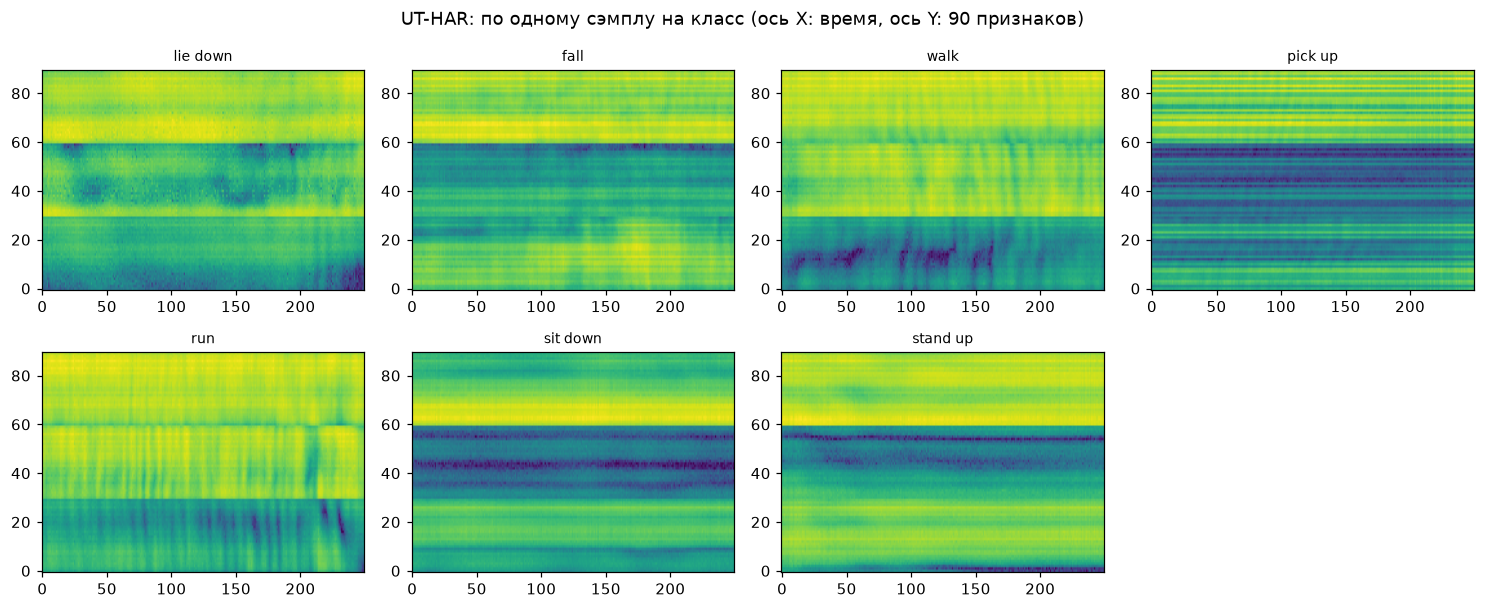

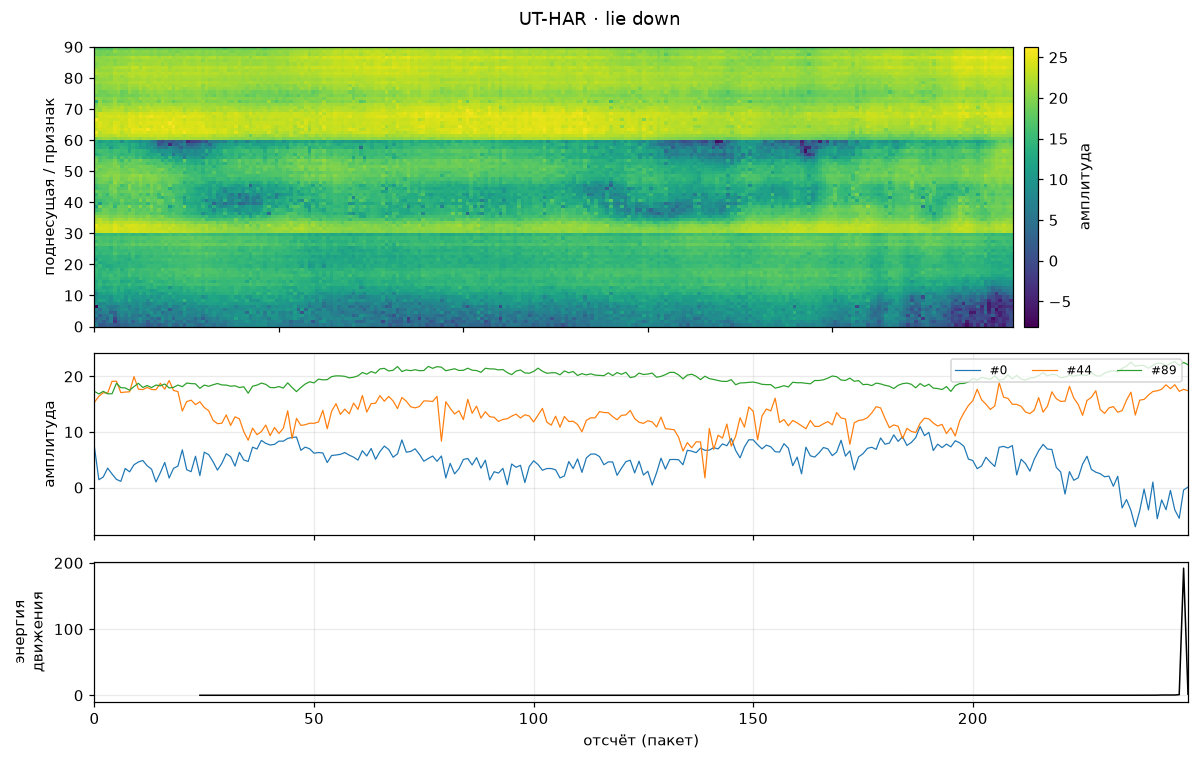

In [5]:
UT_CLASSES = ["lie down", "fall", "walk", "pick up", "run", "sit down", "stand up"]  # сверить!

def find_file(root, stem):
    for p in sorted(Path(root).rglob(stem + "*")):
        if p.is_file():
            return p

def explore_utha(root):
    if not have(root): return
    print("===== UT-HAR =====")
    tree(root, 3)
    data = {}
    for split in ["train", "val", "test"]:
        fx, fy = find_file(root, f"X_{split}"), find_file(root, f"y_{split}")
        if fx is None or fy is None:
            print(f"  нет файлов для split={split}"); continue
        X = np.load(fx, allow_pickle=True); y = np.load(fy, allow_pickle=True).astype(int).ravel()
        X = np.squeeze(X) if X.ndim == 4 else X
        data[split] = (X, y)
        describe(X, f"X_{split}")
        print(f"  y_{split}: {len(y)} меток, классы {np.unique(y)}")
    if not data: return

    X, y = data.get("train", next(iter(data.values())))
    counts = pd.Series(y).value_counts().sort_index()
    names = [UT_CLASSES[i] if i < len(UT_CLASSES) else str(i) for i in counts.index]
    print("\nРаспределение классов (train):")
    print(pd.DataFrame({"класс": names, "n": counts.values}, index=counts.index))

    cls = sorted(np.unique(y))
    ncol = 4; nrow = int(np.ceil(len(cls) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 2.8 * nrow), squeeze=False)
    for ax in axs.ravel(): ax.axis("off")
    for ax, c in zip(axs.ravel(), cls):
        ax.axis("on"); ax.grid(False)
        ax.imshow(to_TF(X[y == c][0]).T, aspect="auto", origin="lower")
        ax.set_title(UT_CLASSES[c] if c < len(UT_CLASSES) else str(c), fontsize=9)
    fig.suptitle("UT-HAR: по одному сэмплу на класс (ось X: время, ось Y: 90 признаков)")
    fig.tight_layout(); plt.show()

    plot_csi(to_TF(X[y == cls[0]][0]), title=f"UT-HAR · {UT_CLASSES[cls[0]]}", win=25)
    for c in cls:
        nm = UT_CLASSES[c] if c < len(UT_CLASSES) else str(c)
        for s in X[y == c][:30]:
            ENERGY["UT_HAR"][nm].append(motion_score(to_TF(s), win=25))

    SUMMARY.append(dict(dataset="UT_HAR", samples=sum(len(v[1]) for v in data.values()),
                        sample_shape=str(X.shape[1:]), n_classes=len(cls), classes=", ".join(UT_CLASSES),
                        has_idle_class="нет (проверить)", note="Intel 5300, 3×30 поднесущих"))

run(explore_utha, PATHS["UT_HAR"])

## 3. Widar 3.0

Датасет жестов рук: много людей, позиций и ориентаций, поэтому он хорош для проверки робастности между доменами. Есть два представления:

- **сырой CSI**: `.dat` файлы формата Intel 5300 (`user*-*-*-*-*-r*.dat`), примерно 1000 пакетов/с;
- **BVP** (body-coordinate velocity profile): `.mat`, матрица скорости по времени.

Для чтения `.dat` нужен пакет `csiread` (`pip install csiread`). Смысл полей имени файла (по описанию датасета, проверьте): `user – жест – позиция – ориентация – повтор – приёмник`.

In [ ]:
WIDAR_RE = re.compile(r"user(\d+)-(\d+)-(\d+)-(\d+)-(\d+)-r(\d+)")

def explore_widar(raw_root, bvp_root, fs=1000):
    print("===== Widar 3.0: сырой CSI =====")
    if have(raw_root):
        tree(raw_root, 3)
        dats = sorted(Path(raw_root).rglob("*.dat"))
        print("\n.dat файлов:", len(dats))
        rows = []
        for p in dats:
            m = WIDAR_RE.search(p.name)
            if m: rows.append(dict(zip(["user", "gesture", "position", "orientation", "repeat", "receiver"],
                                       map(int, m.groups())), path=p))
        meta = pd.DataFrame(rows)
        if len(meta):
            print("\nЧисло различных значений в имени файла:")
            print(meta.drop(columns="path").nunique())
        try:
            import csiread
            p = dats[0]
            cs = csiread.Intel(str(p), nrxnum=3, ntxnum=1, pl_size=10, if_report=False)
            cs.read()
            csi = cs.csi                      # (N, 30, 3, 1)
            describe(csi, f"\n{p.name}: csiread.csi")
            amp = np.abs(csi).reshape(csi.shape[0], -1)
            plot_csi(amp, fs=fs, title=f"Widar 3.0 · {p.name}", win=100, max_t=5000)
            ENERGY["Widar3.0"]["gesture " + str(meta.gesture.iloc[0] if len(meta) else "?")].append(motion_score(amp, 100))
            SUMMARY.append(dict(dataset="Widar3.0 (raw)", samples=len(dats), sample_shape=str(csi.shape[1:]) + " × N",
                                n_classes=int(meta.gesture.nunique()) if len(meta) else None, classes="жесты рук",
                                has_idle_class="нет", note="Intel 5300, ~1 кГц, много доменов"))
        except ImportError:
            print("\n[!] csiread не установлен: pip install csiread  (чтение .dat пропущено)")
    print("\n===== Widar 3.0: BVP =====")
    if have(bvp_root):
        tree(bvp_root, 3)
        mats = sorted(Path(bvp_root).rglob("*.mat"))
        print(".mat файлов:", len(mats))
        if mats:
            m = sio.loadmat(mats[0])
            for k, v in m.items():
                if isinstance(v, np.ndarray): print(f"  ключ {k}: shape={v.shape}, dtype={v.dtype}")
            arrs = [v for v in m.values() if isinstance(v, np.ndarray) and v.ndim == 3]
            if arrs:
                v = arrs[0]; T = v.shape[-1]
                idx = np.linspace(0, T - 1, min(6, T)).astype(int)
                fig, axs = plt.subplots(1, len(idx), figsize=(2.6 * len(idx), 2.8))
                for ax, i in zip(np.atleast_1d(axs), idx):
                    ax.imshow(v[..., i], origin="lower"); ax.set_title(f"кадр {i}", fontsize=9); ax.grid(False)
                fig.suptitle(f"BVP: {mats[0].name}"); plt.show()

run(explore_widar, PATHS["Widar_raw"], PATHS["Widar_BVP"])

## 4. Wallhack1.8k

ESP32, сценарии LoS и NLoS (сквозь стену). Классы: «нет присутствия», «ходьба», «ходьба + махание руками» (по описанию на Zenodo). Каждая строка csv содержит один Wi-Fi пакет: комплексный CSI в поле `data`, метка в поле `class`. В архиве также лежат спектрограммы амплитуды.

Ниже CSI парсится как пары `(imag, real)` (формат ESP-IDF); точный выбор поднесущих сверьте с даталоадером из репозитория.

===== Wallhack1.8k =====
C:\Users\ditriy\Desktop\wifi-csi-scene\data\wallhack1.8k
LOS/   (2 элементов)
    BQ/   (12 элементов)
        spectrograms/   (466 элементов)
            0.png   0.01 MB
            1.png   0.01 MB
            10.png   0.01 MB
            100.png   0.01 MB
            101.png   0.01 MB
            102.png   0.01 MB
            103.png   0.01 MB
            104.png   0.01 MB
            ... ещё 458 файлов
        b1.csv   49.83 MB
        w1.csv   10.68 MB
        w2.csv   10.10 MB
        w3.csv   10.64 MB
        w4.csv   10.55 MB
        w5.csv   11.19 MB
        ww1.csv   10.53 MB
        ww2.csv   10.32 MB
        ... ещё 3 файлов
    PIFA/   (12 элементов)
        spectrograms/   (469 элементов)
            0.png   0.01 MB
            1.png   0.01 MB
            10.png   0.01 MB
            100.png   0.01 MB
            101.png   0.01 MB
            102.png   0.01 MB
            103.png   0.01 MB
            104.png   0.01 MB
            ... ещё 461 файло

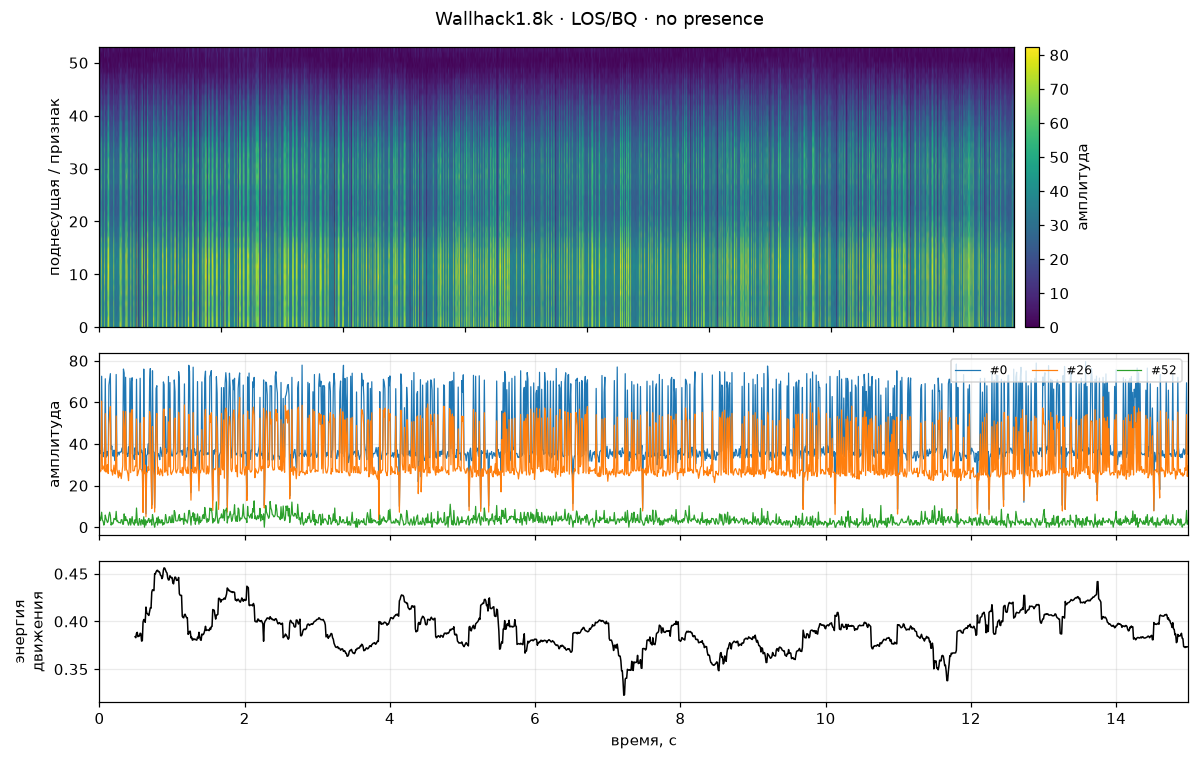

LOS/BQ · класс 1 (w1.csv): shape=(1500, 53), dtype=float64, min=0, max=151, mean=35, std=17, nan=0, inf=0


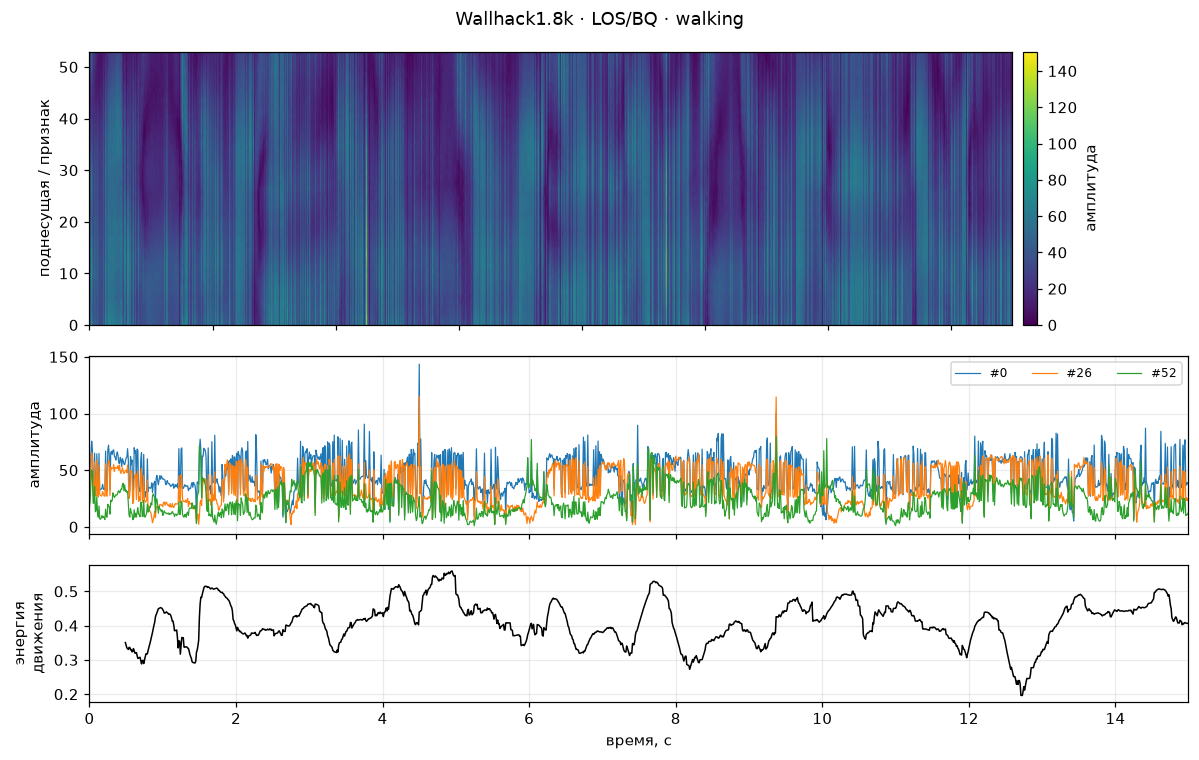

LOS/BQ · класс 2 (ww1.csv): shape=(1500, 53), dtype=float64, min=0, max=136, mean=36.2, std=17.2, nan=0, inf=0


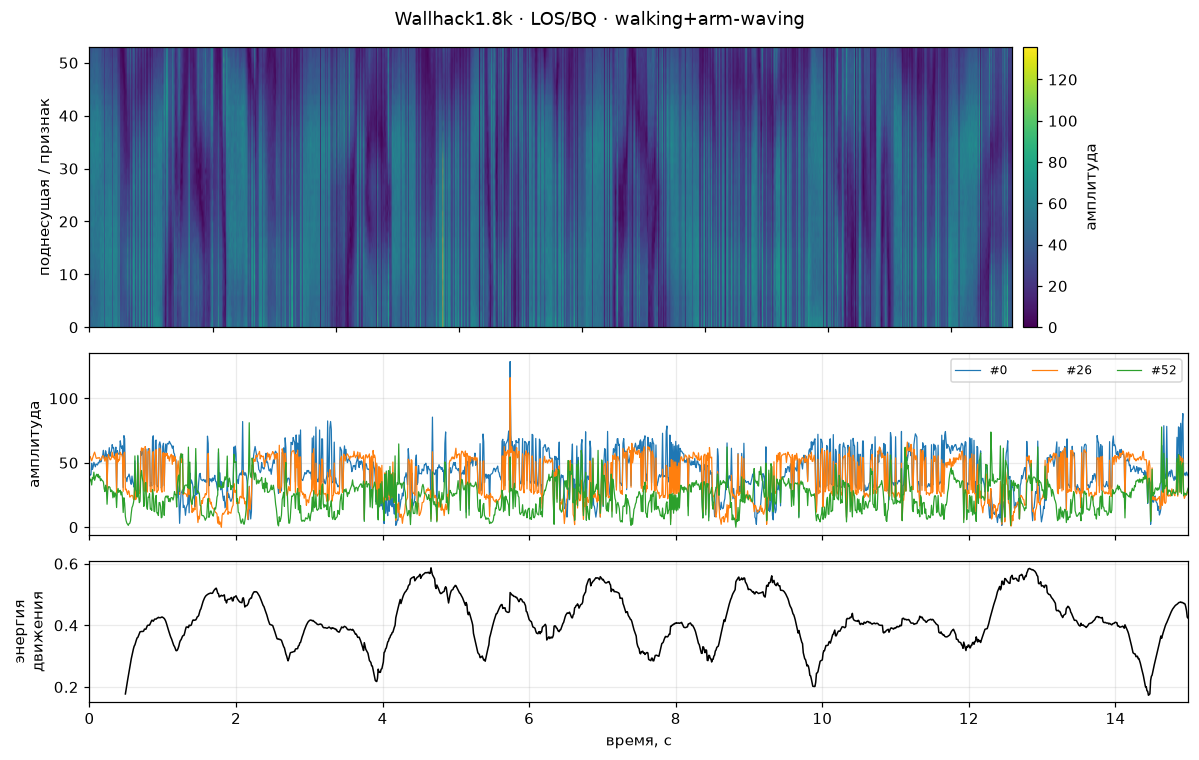

NLOS/BQ · класс 0 (b1.csv): shape=(1500, 53), dtype=float64, min=0, max=81.5, mean=46.4, std=15.5, nan=0, inf=0


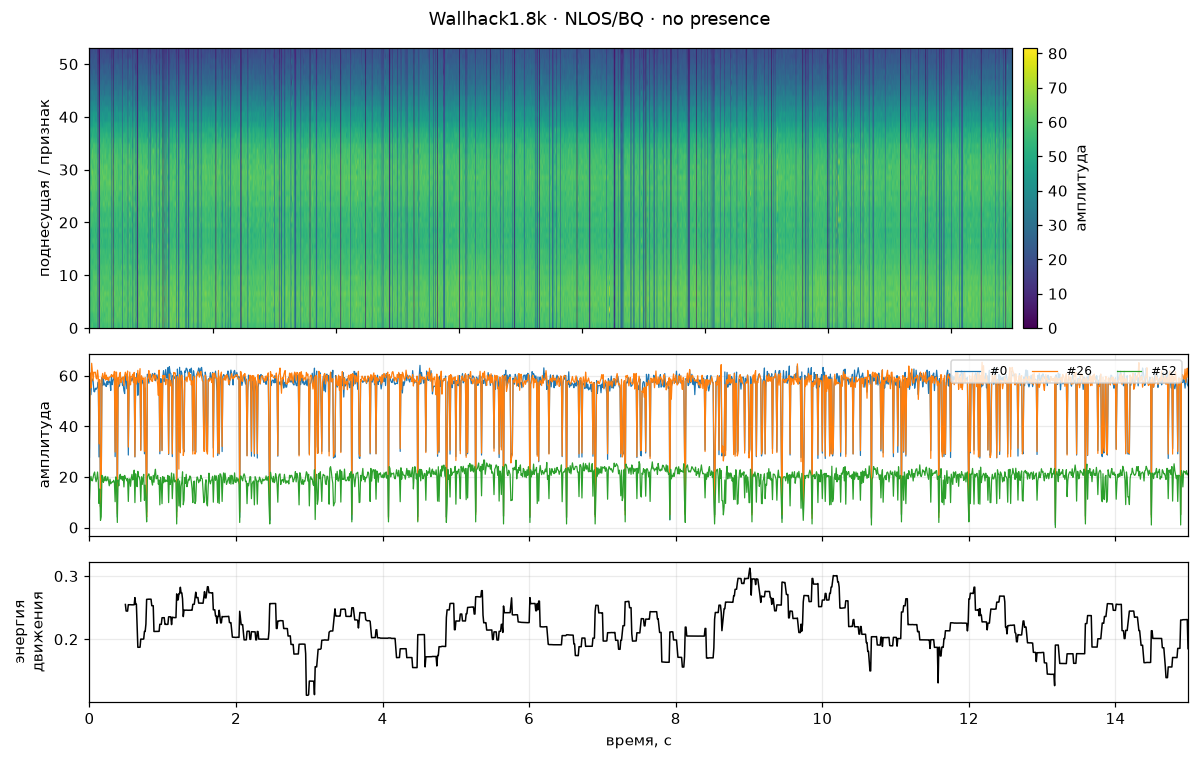

NLOS/BQ · класс 1 (w1.csv): shape=(1500, 53), dtype=float64, min=0, max=142, mean=43.1, std=16.7, nan=0, inf=0


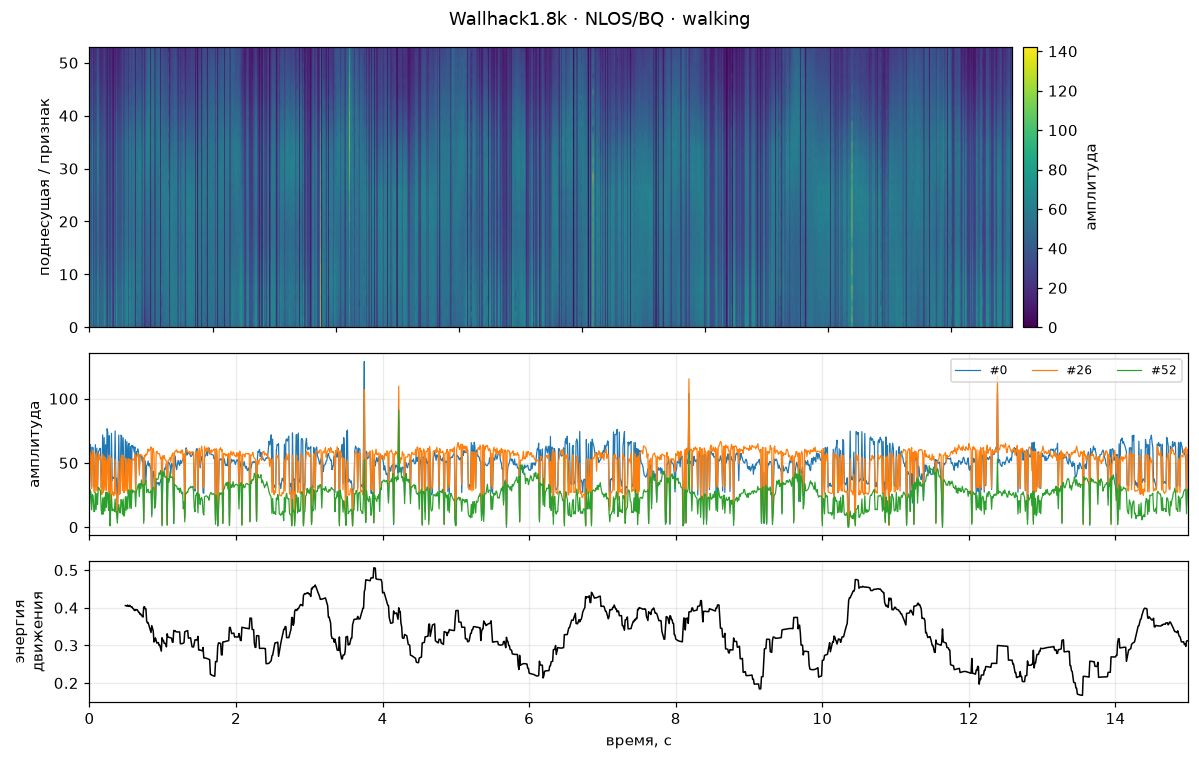

NLOS/BQ · класс 2 (ww1.csv): shape=(1500, 53), dtype=float64, min=0, max=180, mean=44.4, std=15.8, nan=0, inf=0


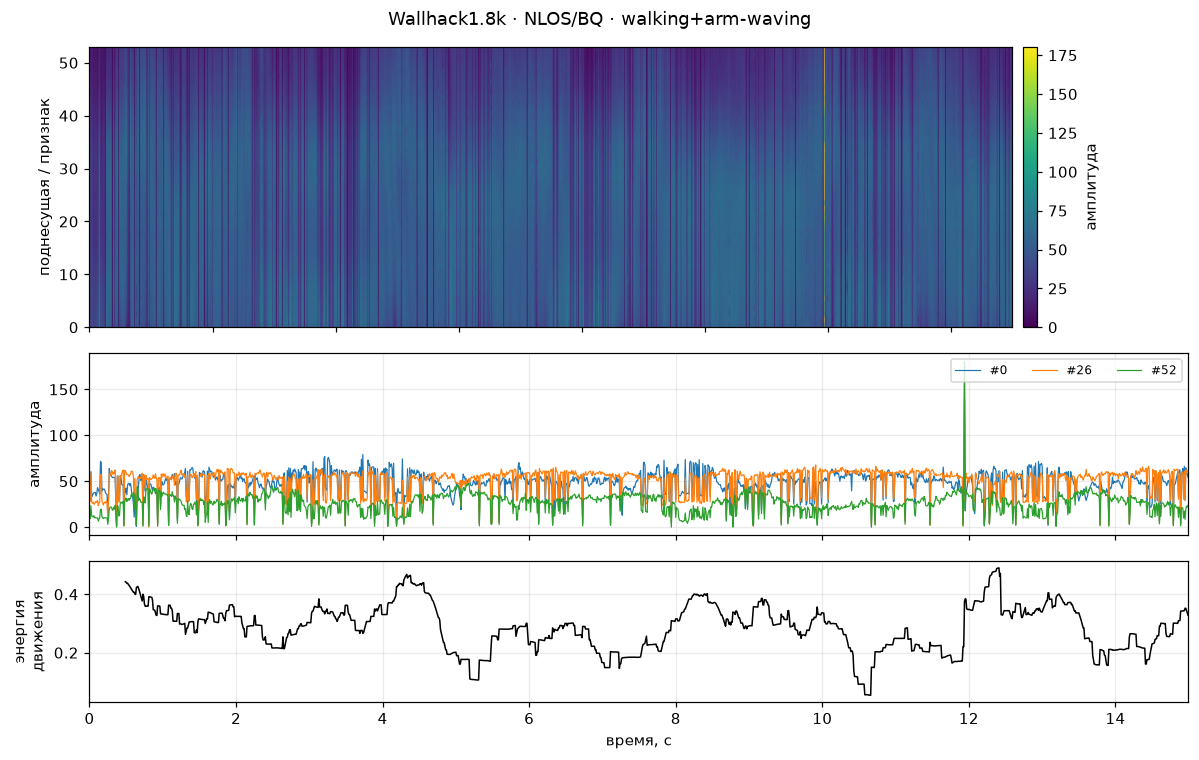

In [9]:
WALLHACK_VALID = list(range(66, 94)) + list(range(95, 123))   # 256 значений = 128 комплексных поднесущих
WALLHACK_FS = 100                                             # по local_timestamp шаг ~10 мс
WALLHACK_NAMES = {0: "no presence", 1: "walking", 2: "walking+arm-waving"}

def csi_rows_to_amp(df, valid=None):
    csi = np.stack([parse_csi_cell(s) for s in df["data"]])
    if valid is not None and csi.shape[1] > max(valid):
        csi = csi[:, valid]
    amp = np.abs(csi)
    return amp[:, amp.std(0) > 0]          # выбрасываем «нулевые» поднесущие

def raw_csvs(d):
    """Сырые csv пакетов: только в папке сценария, без spectrograms/."""
    out = []
    for p in sorted(Path(d).glob("*.csv")):
        cols = pd.read_csv(p, nrows=0).columns
        if {"data", "class"} <= set(cols):
            out.append(p)
    return out

def explore_wallhack(root, rows=6000, scenarios=("LOS/BQ", "NLOS/BQ")):
    if not have(root): return
    root = Path(root)
    print("===== Wallhack1.8k =====")
    tree(root, 4)

    # --- все сырые csv и служебные csv ---
    scen_dirs = sorted(p for p in root.glob("*/*") if p.is_dir())
    all_raw = {d: raw_csvs(d) for d in scen_dirs}
    n_raw = sum(len(v) for v in all_raw.values())
    service = sorted(p for p in root.rglob("*.csv") if "spectrograms" in p.parts)
    pngs = sum(1 for _ in root.rglob("*.png"))
    print(f"\nсырых csv: {n_raw} | служебных csv в spectrograms/: {len(service)} | png: {pngs}")
    if service:
        print("служебные файлы:", sorted({p.name for p in service}))
        print(pd.read_csv(service[0], nrows=5))
    if not n_raw: return

    first = next(v[0] for v in all_raw.values() if v)
    head = pd.read_csv(first, nrows=3)
    print("\nКолонки:", list(head.columns))
    print(head.drop(columns=["data"]).iloc[:, [0, 1, 3, 10, 18, 22, -4, -3, -2, -1]])

    # --- пакеты по файлам и классам ---
    stats = []
    for d, files in all_raw.items():
        for p in files:
            c = pd.read_csv(p, usecols=["class"])["class"]
            stats.append({"file": str(p.relative_to(root)), "packets": len(c),
                          **{f"class_{k}": v for k, v in c.value_counts().to_dict().items()}})
    st = pd.DataFrame(stats).fillna(0)
    print("\nПакеты по файлам и классам:")
    print(st.to_string(index=False))
    print("\nИтого пакетов по сценариям и классам:")
    st["scenario"] = st.file.str.rsplit("\\", n=1).str[0].str.rsplit("/", n=1).str[0]
    print(st.groupby("scenario").sum(numeric_only=True))

    # --- примеры по классам для выбранных сценариев ---
    for scen in scenarios:
        d = root / Path(scen)
        files = all_raw.get(d, [])
        if not files:
            print(f"[пропуск] сценарий {scen}: нет сырых csv"); continue
        got = {}
        for p in files:
            df = pd.read_csv(p, nrows=rows)
            for c in df["class"].unique():
                if c in got: continue
                part = df[df["class"] == c].head(1500)
                if len(part) > 200:
                    got[c] = (p, csi_rows_to_amp(part, WALLHACK_VALID))
            if len(got) >= 3: break
        for c, (p, amp) in sorted(got.items()):
            nm = WALLHACK_NAMES.get(c, str(c))
            describe(amp, f"{scen} · класс {c} ({p.name})")
            plot_csi(amp, fs=WALLHACK_FS, title=f"Wallhack1.8k · {scen} · {nm}", win=50)
            for i in range(0, len(amp) - 400, 400):
                ENERGY[f"Wallhack1.8k {scen}"][nm].append(motion_score(amp[i:i + 400], 50))

    SUMMARY.append(dict(dataset="Wallhack1.8k", samples=f"{n_raw} csv, {pngs} png",
                        sample_shape="пакеты × 128 компл. поднесущих (выбрано 56)",
                        n_classes=3, classes=", ".join(WALLHACK_NAMES.values()),
                        has_idle_class="да (no presence)",
                        note="ESP32, 100 Гц, LoS/NLoS × BQ/PIFA, есть x,y,z и спектрограммы"))

run(explore_wallhack, PATHS["Wallhack1.8k"])

## 5. 3DO (датасет по ссылке из саммари)

42 пятиминутные записи одного человека за 3 дня, через стену. Метки: фон (0), ходьба (1), сидение (2), лежание (3) плюс 3D-траектория. Структура: `d1/d2/d3` → папки записей (`w1`, `s1`, `l1`, `b1` …) → `csiposreg.csv` и `csiposreg_complex.npy`.

Здесь особенно интересно сравнить **фон, ходьбу и статичные позы** (сидение, лежание): человек присутствует, но почти не двигается. Это естественный сложный случай для бинарного классификатора «есть/нет движения». Ещё есть три дня записей, то есть готовый тест на дрейф домена.

===== 3DO =====
C:\Users\ditriy\Desktop\wifi-csi-scene\data\3DO
d1/   (18 элементов)
    b1/   (3 элементов)
        csi.csv   50.92 MB
        csiposreg.csv   51.51 MB
        csiposreg_complex.npy   24.51 MB
    b2/   (3 элементов)
        csi.csv   52.20 MB
        csiposreg.csv   52.80 MB
        csiposreg_complex.npy   25.07 MB
    b3/   (3 элементов)
        csi.csv   51.17 MB
        csiposreg.csv   51.76 MB
        csiposreg_complex.npy   24.59 MB
    l1/   (2 элементов)
        csiposreg.csv   28.76 MB
        csiposreg_complex.npy   12.98 MB
    l2/   (2 элементов)
        csiposreg.csv   28.59 MB
        csiposreg_complex.npy   12.87 MB
    l3/   (2 элементов)
        csiposreg.csv   28.72 MB
        csiposreg_complex.npy   12.94 MB
    l4/   (2 элементов)
        csiposreg.csv   28.13 MB
        csiposreg_complex.npy   12.77 MB
    l5/   (2 элементов)
        csiposreg.csv   28.52 MB
        csiposreg_complex.npy   12.86 MB
    ... ещё 10 папок
d2/   (18 элементов)
    b1/ 

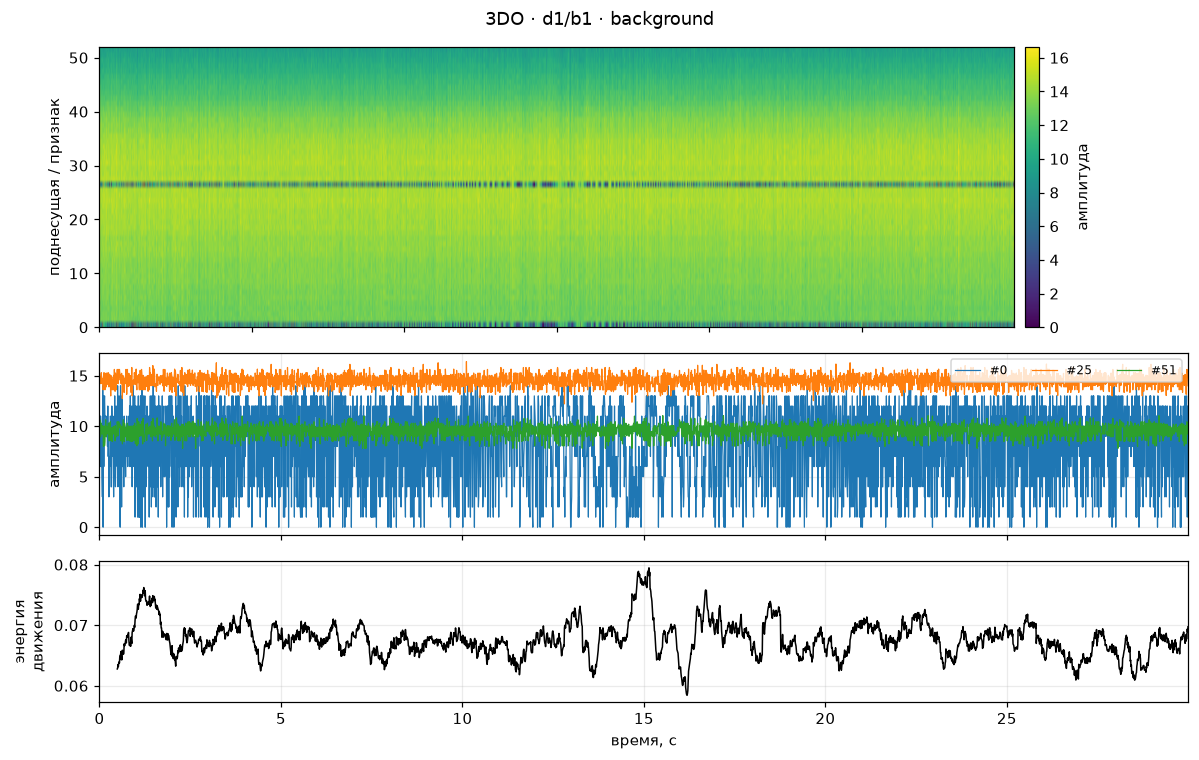

d1/l1: shape=(3000, 52), dtype=float32, min=0, max=33.1, mean=12.9, std=2.46, nan=0, inf=0


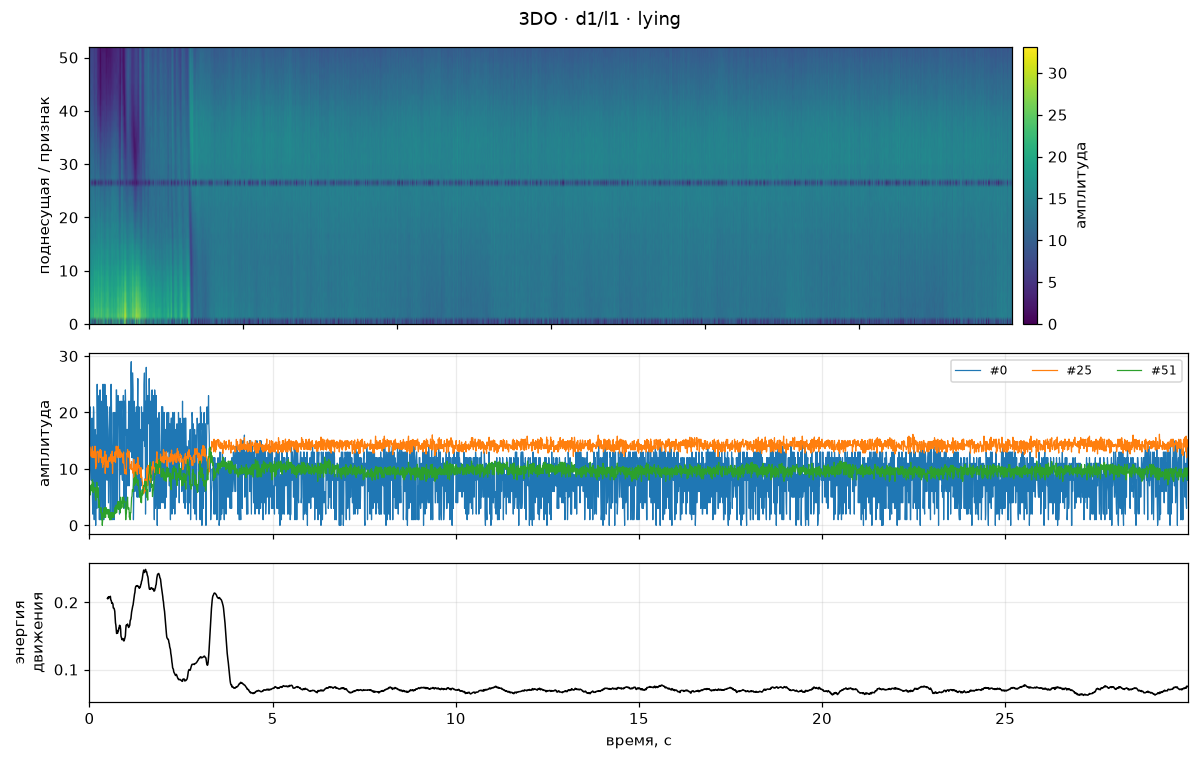

d1/s1: shape=(3000, 52), dtype=float32, min=0, max=31.8, mean=12.8, std=2.6, nan=0, inf=0


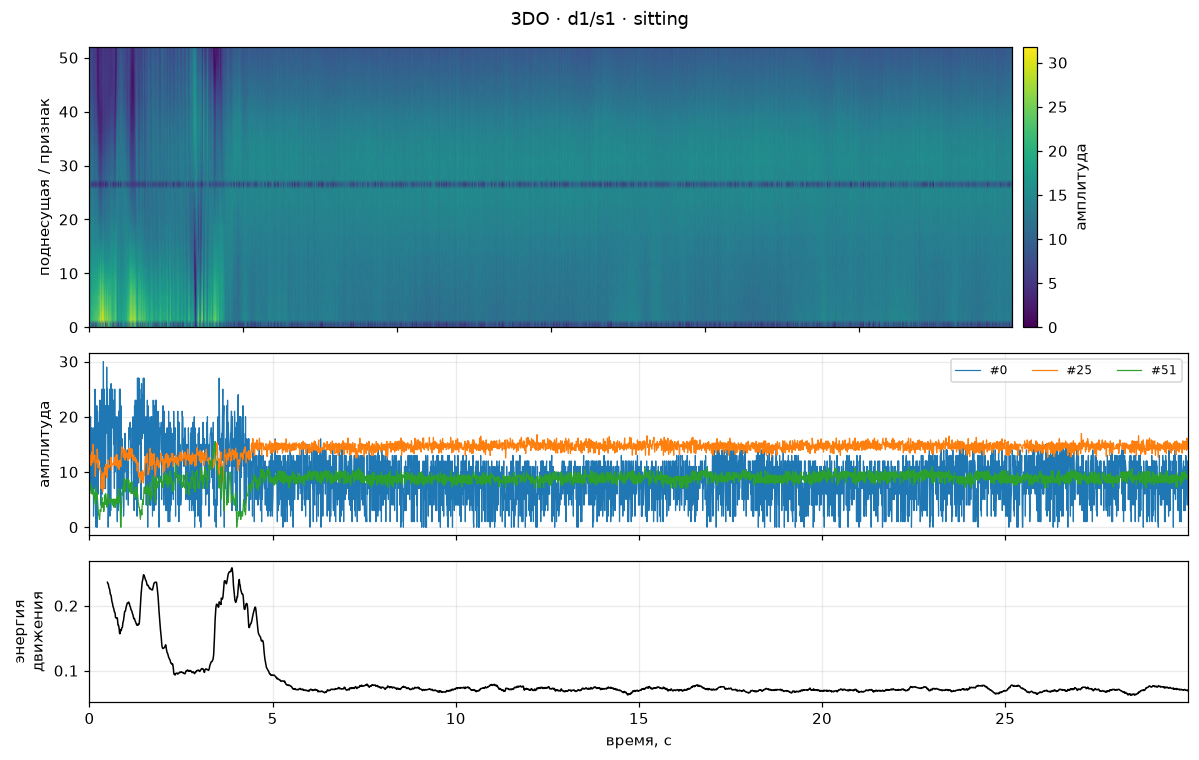

d1/w1: shape=(3000, 52), dtype=float32, min=0, max=32.8, mean=12.7, std=3, nan=0, inf=0


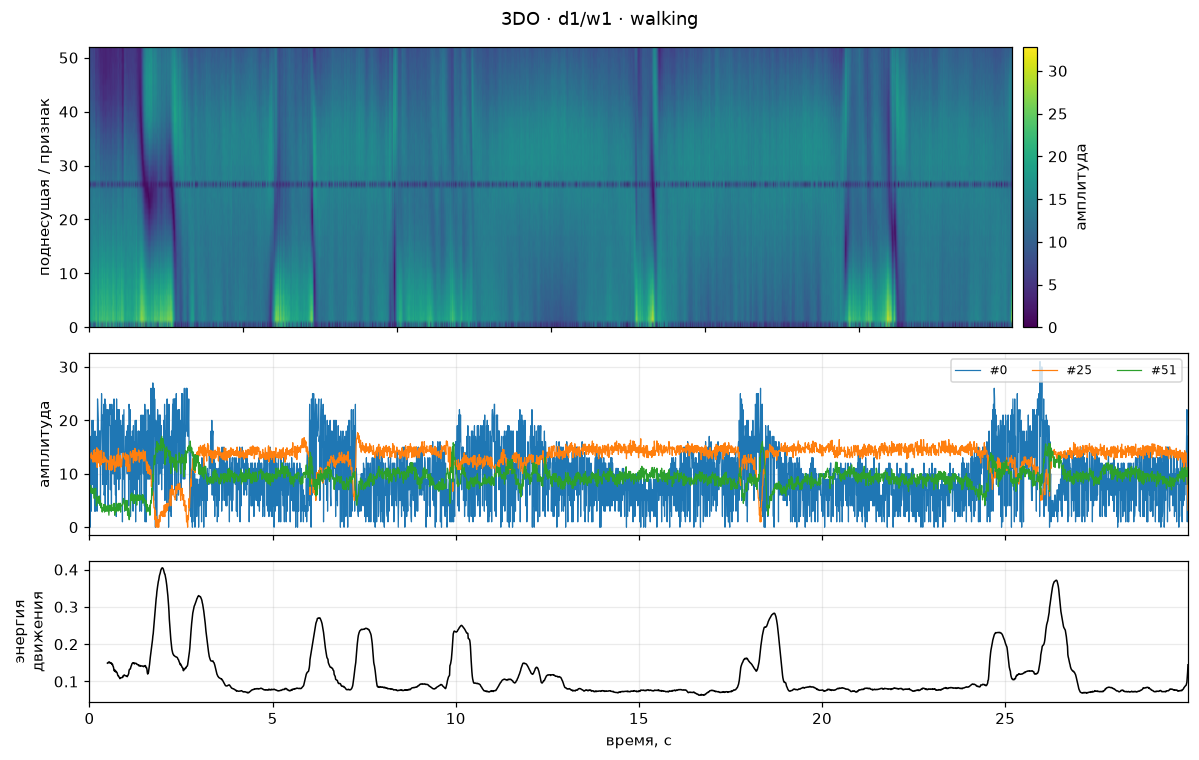

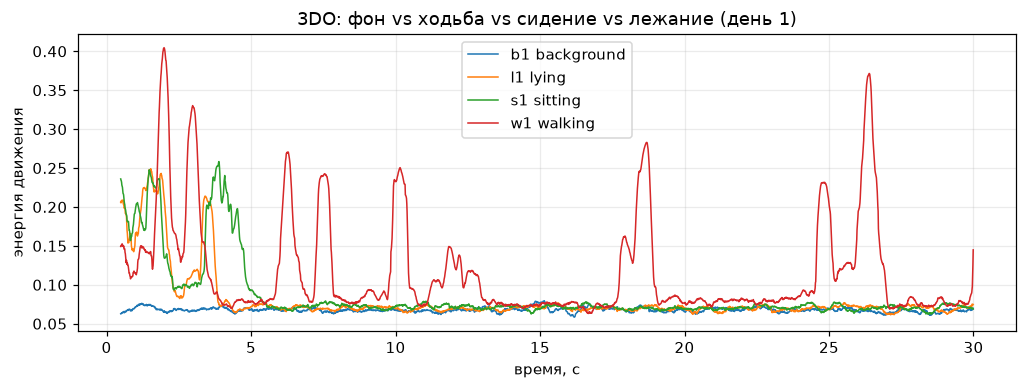


Колонки csv: ['type', 'id', 'mac', 'rssi', 'rate', 'sig_mode', 'mcs', 'bandwidth', 'smoothing', 'not_sounding', 'aggregation', 'stbc', 'fec_coding', 'sgi', 'noise_floor', 'ampdu_cnt', 'channel', 'secondary_channel', 'local_timestamp', 'ant', 'sig_len', 'rx_state', 'len', 'first_word', 'data', 'class', 'x', 'y', 'z']
       type  id                mac  rssi  rate  sig_mode  mcs  bandwidth  \
0  CSI_DATA   0  1a:00:00:00:00:00   -39    11         1    0          0   
1  CSI_DATA   1  1a:00:00:00:00:00   -39    11         1    0          0   
2  CSI_DATA   2  1a:00:00:00:00:00   -39    11         1    0          0   

   smoothing  not_sounding  ...  local_timestamp  ant  sig_len  rx_state  len  \
0          1             1  ...        250209465    0       44         0  256   
1          1             1  ...        250218849    0       44         0  256   
2          1             1  ...        250228856    0       44         0  256   

   first_word  class  x  y  z  
0           0      

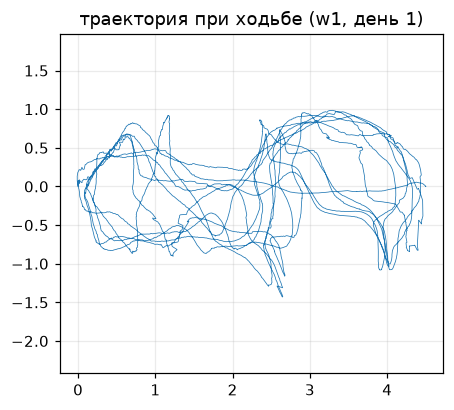

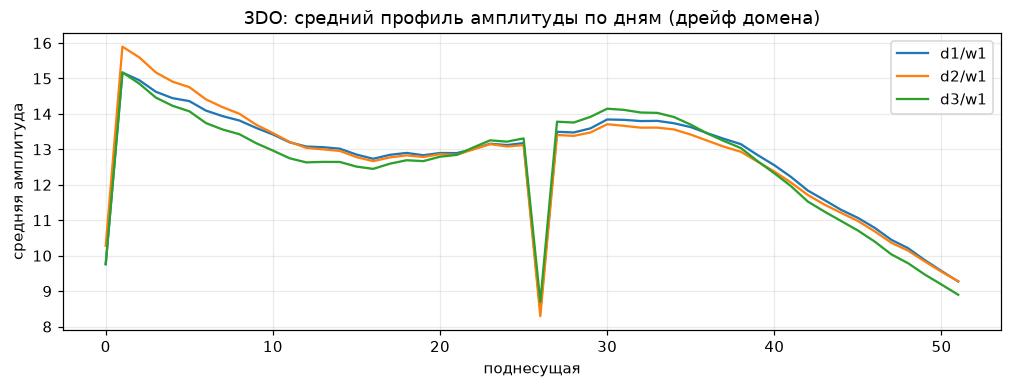

In [7]:
def explore_3do(root, fs=100, n=3000):
    if not have(root): return
    root = Path(root)
    print("===== 3DO =====")
    tree(root, 3)
    seqs = sorted(p for p in root.glob("d*/*") if p.is_dir())
    names = {"b": "background", "w": "walking", "s": "sitting", "l": "lying"}
    print("\nзаписей:", len(seqs))

    def load_amp(seq, n=None):
        f = seq / "csiposreg_complex.npy"
        if f.exists():
            a = np.load(f, mmap_mode="r")
            return np.abs(np.asarray(a[:n] if n else a))
        print(f"  нет {f.name}, читаю csv (медленнее)")
        df = pd.read_csv(seq / "csiposreg.csv", nrows=n)
        return csi_rows_to_amp(df)

    ref = [s for s in seqs if s.parent.name == "d1" and s.name in ("b1", "w1", "s1", "l1")] or seqs[:4]
    curves = {}
    for s in ref:
        a = to_TF(load_amp(s, n))
        describe(a, f"{s.parent.name}/{s.name}")
        plot_csi(a, fs=fs, title=f"3DO · {s.parent.name}/{s.name} · {names.get(s.name[0], s.name)}", win=50)
        curves[f"{s.name} {names.get(s.name[0], '')}"] = motion_curve(a, 50)

    plt.figure(figsize=(11, 3.5))
    for k, v in curves.items():
        plt.plot(np.arange(len(v)) / fs, v, label=k, lw=1)
    plt.xlabel("время, с"); plt.ylabel("энергия движения"); plt.legend()
    plt.title("3DO: фон vs ходьба vs сидение vs лежание (день 1)"); plt.show()

    # CSV: метки и траектории
    csv = next((s / "csiposreg.csv" for s in ref if (s / "csiposreg.csv").exists()), None)
    if csv is not None:
        head = pd.read_csv(csv, nrows=3)
        print("\nКолонки csv:", list(head.columns))
        print(head.drop(columns=[c for c in ["data"] if c in head.columns]))
        wcsv = next((s / "csiposreg.csv" for s in ref if s.name.startswith("w")), None)
        if wcsv is not None and {"x", "y"} <= set(head.columns):
            tr = pd.read_csv(wcsv, usecols=["x", "y"])
            plt.figure(figsize=(4.5, 4)); plt.plot(tr.x, tr.y, lw=0.5); plt.axis("equal")
            plt.title("траектория при ходьбе (w1, день 1)"); plt.show()

    # дрейф между днями
    plt.figure(figsize=(11, 3.5))
    for s in [s for s in seqs if s.name == "w1"]:
        a = to_TF(load_amp(s, n))
        plt.plot(a.mean(0), label=f"{s.parent.name}/w1")
    plt.xlabel("поднесущая"); plt.ylabel("средняя амплитуда"); plt.legend()
    plt.title("3DO: средний профиль амплитуды по дням (дрейф домена)"); plt.show()

    for s in seqs:
        ENERGY["3DO"][names.get(s.name[0], s.name)].append(motion_score(to_TF(load_amp(s, 6000)), 50))

    SUMMARY.append(dict(dataset="3DO", samples=f"{len(seqs)} записей", sample_shape="(пакеты × поднесущие), комплексный",
                        n_classes=4, classes="background, walking, sitting, lying",
                        has_idle_class="да (background) + статичные позы", note="ESP32, через стену, 3 дня, ~100 Гц (оценка)"))

run(explore_3do, PATHS["3DO"])

## 6. Сводка по датасетам

In [8]:
summary = pd.DataFrame(SUMMARY)
pd.set_option("display.max_colwidth", 80, "display.width", 200)
summary

,dataset,samples,sample_shape,n_classes,classes,has_idle_class,note
0,UT_HAR,4973,"(250, 90)",7,"lie down, fall, walk, pick up, run, sit down, stand up",нет (проверить),"Intel 5300, 3×30 поднесущих"
1,3DO,51 записей,"(пакеты × поднесущие), комплексный",4,"background, walking, sitting, lying",да (background) + статичные позы,"ESP32, через стену, 3 дня, ~100 Гц (оценка)"


## 7. Реагирует ли «энергия движения» на классы?

Для каждого датасета: распределение `motion_score` по классам (скользящее std/mean амплитуды, усреднённое по поднесущим). Это грубая проверка идеи «движение → больше изменчивость CSI». Что искать:

- отделяется ли фон / «нет присутствия» от остальных классов;
- где статичные позы (сидение, лежание в 3DO) лежат относительно фона и ходьбы;
- насколько шкалы разных датасетов вообще сопоставимы (скорее всего, нет, поэтому сравнивать нужно внутри датасета).

In [ ]:
avail = {k: v for k, v in ENERGY.items() if len(v)}
if not avail:
    print("Нет данных: ни одна секция выше не отработала.")
else:
    n = len(avail); ncol = min(3, n); nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 3.8 * nrow), squeeze=False)
    for ax in axs.ravel(): ax.axis("off")
    for ax, (ds, d) in zip(axs.ravel(), avail.items()):
        ax.axis("on")
        labels = list(d.keys())
        ax.boxplot([d[k] for k in labels], labels=labels, showfliers=False)
        ax.set_title(ds); ax.set_ylabel("motion_score")
        ax.tick_params(axis="x", rotation=40)
    fig.tight_layout(); plt.show()

## 8. Заметки для обсуждения (заполнить после просмотра)

- Какие датасеты содержат явный класс «нет движения/человека»? Для остальных как строить бинарную разметку?
- Что считать «нет движения»: пустая комната или присутствие неподвижного человека?
- Частота и длина окна: насколько отличаются между датасетами, нужна ли ресемплинг-нормализация?
- Амплитуда или комплексный CSI/фаза: что доступно во всех датасетах (общий знаменатель)?
- Какие оси домена есть (день, комната, человек, позиция, ориентация) и как из них собрать тесты на робастность?
- Артефакты: `inf`/`nan`, нулевые поднесущие, дрейф средней амплитуды.